> 🔓 **SOLUTIONS EDITION**: this is the instructor copy with worked solutions and executed outputs. Please attempt every problem in the student notebook first; struggling is where learning happens.

# 📘 Lesson 12: Random Forest Classification
*A jury of decorrelated trees: majority wisdom, probabilities and a free validation score*

| ⏱️ Time | 🎚️ Level | 🧰 Prerequisites |
|---|---|---|
| ~120 min | 🟡 Intermediate | Lessons 05 and 11 |

---
## 🎬 The Hook
Imagine a jury of 101 people deciding guilty/not guilty, where each juror is right just **60 %** of the time: barely better than a coin flip. If their errors were independent, the **majority verdict is right about 98 % of the time**. That's the 18th-century *Condorcet jury theorem*, and it is the whole secret of Random Forests: take many mediocre-but-different voters and let them vote.

The catch: the voters must be **different**. 101 jurors who all read the same newspaper make one decision 101 times. Much of the engineering in a Random Forest is about keeping the trees *diverse*.

---
## 🎯 Learning Objectives
By the end of this notebook you will be able to:

1. Explain why a majority vote of **independent, better-than-chance** voters is so powerful (Condorcet's jury theorem) and why correlation limits it.
2. Distinguish **hard** (majority) voting from **soft** (probability-averaging) voting, and know which scikit-learn uses.
3. Implement a Random Forest classifier **from scratch** with bootstrap sampling, feature subsets and an OOB score.
4. Tune `n_estimators`, `max_features`, `min_samples_leaf`, `max_depth` and `class_weight`.
5. Read probability quality with calibration curves and interpret a forest via permutation importance.
6. Handle class imbalance with `class_weight` and PR-AUC.
7. Know when a forest beats logistic regression, and when it doesn't.

## 🗺️ Roadmap

- Condorcet and the power (and limit) of voting
- Hard vs soft voting
- From scratch: the forest classifier with OOB
- Seeing the forest smooth the boundary
- Tuning: how many trees, how many features
- Probability quality: calibration
- Loan approvals: forest vs tree vs logistic regression
- Imbalanced data & class weights
- Interpreting with permutation importance
- Cheat-sheet, worked examples, problems, quiz

> 💡 **How to use this notebook:** run cells top to bottom. Read the text *before* you run the code. When you reach a 🧩 **Problem**, try it yourself first, open the hints one at a time, and only then peek at the solutions notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))      # so we can import course_utils.py
from course_utils import *                      # np, pd, plt, check(), data_path(), ...
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
RANDOM_STATE = 42
print("Setup complete ✅")
from sklearn.datasets import make_moons, make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score, recall_score, precision_score, confusion_matrix
from scipy.stats import binom

Setup complete ✅


---
## 🗳️ 1. Condorcet and the power (and limit) of voting

If $n$ voters (odd) are each correct with probability $p>0.5$, **independently**, the chance that the majority is correct is a binomial tail:

$$P(\text{majority correct})=\sum_{k>n/2}\binom nk p^k(1-p)^{n-k}$$

Let's compute it, and then see what happens when the voters are partly *copies* of each other (a fraction ρ of the time everybody follows the same leader).

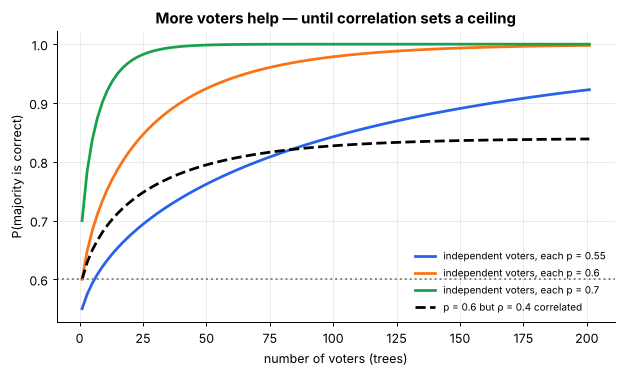

101 independent voters with p=0.6 -> majority is right 97.9% of the time
...but with correlation ρ=0.4 the ceiling is only 84.0%


In [2]:
ns = np.arange(1, 202, 2)
fig, ax = plt.subplots(figsize=(8, 4.2))
for p in [0.55, 0.6, 0.7]:
    ax.plot(ns, binom.sf(ns // 2, ns, p), lw=2.2, label=f"independent voters, each p = {p}")
# correlated jury: with probability rho all voters copy ONE shared opinion (correct w.p. p); otherwise they vote independently
p, rho = 0.6, 0.4
ax.plot(ns, rho * p + (1 - rho) * binom.sf(ns // 2, ns, p), "k--", lw=2.2, label=f"p = 0.6 but ρ = {rho} correlated")
ax.axhline(p, color="gray", ls=":"); ax.set_xlabel("number of voters (trees)"); ax.set_ylabel("P(majority is correct)"); ax.legend(fontsize=8); ax.set_title("More voters help; until correlation sets a ceiling"); plt.show()
print(f"101 independent voters with p=0.6 -> majority is right {binom.sf(50, 101, 0.6):.1%} of the time")
print(f"...but with correlation ρ=0.4 the ceiling is only {rho * p + (1 - rho):.1%}")

> 🔑 **Key idea.**
>
> **Ensemble accuracy rests on two legs:** each voter must beat chance (we use deep trees: low bias), and the voters' errors must be as *independent* as possible. Random Forests create diversity with (1) **bootstrap samples**: each tree sees a different ~63 % of the rows: and (2) **random feature subsets** at every split: each split sees only `max_features` randomly chosen columns (default √p for classification).

---
## ⚖️ 2. Hard vs soft voting

How do we combine the trees' answers?

- **Hard voting:** each tree votes for a class; the majority wins.
- **Soft voting:** average the trees' **predicted probabilities** (each leaf's class proportions) and take the class with the highest average. This uses more information (a tree that is 90 % sure counts more than one that is 51 % sure). **scikit-learn's forest uses soft voting.**

In [3]:
tree_probs = np.array([0.90, 0.45, 0.45])                    # P(class 1) from three trees
hard = (tree_probs >= 0.5).mean() > 0.5                       # votes: 1, 0, 0  -> class 0 wins 2-1
soft = tree_probs.mean() >= 0.5                               # average = 0.60 -> class 1
print(f"hard vote -> class {int(hard)}   |   soft vote (mean prob = {tree_probs.mean():.2f}) -> class {int(soft)}")

hard vote -> class 0   |   soft vote (mean prob = 0.60) -> class 1


Here the two rules *disagree*: one very confident tree outweighs two lukewarm ones under soft voting. In practice soft voting is usually slightly better and also produces probabilities.

---
## 🔧 3. Build it from scratch

The same recipe as Lesson 05, but with `DecisionTreeClassifier` base trees, class probabilities, soft *or* hard voting, and an OOB accuracy. One subtlety: with few classes a bootstrap sample can (rarely) miss a class entirely, so each tree's probability columns must be mapped back onto the full class list.

In [4]:
class RandomForestClassifierScratch:
    """Random forest classifier: bootstrap rows + random feature subsets + (soft or hard) voting + OOB estimate."""

    def __init__(self, n_estimators=100, max_features="sqrt", min_samples_leaf=1, max_depth=None, voting="soft", random_state=0):
        self.n_estimators, self.max_features, self.min_samples_leaf = n_estimators, max_features, min_samples_leaf
        self.max_depth, self.voting, self.random_state = max_depth, voting, random_state

    def _tree_proba(self, tree, X):                        # map a tree's class columns back onto the full class list
        P = np.zeros((len(X), self.K_)); P[:, tree.classes_] = tree.predict_proba(X); return P

    def fit(self, X, y):
        X = np.asarray(X, float); self.classes_, yi = np.unique(y, return_inverse=True); self.K_ = len(self.classes_); n = len(yi)
        rng = np.random.default_rng(self.random_state); self.trees_ = []
        oob_sum, oob_cnt = np.zeros((n, self.K_)), np.zeros(n)
        for _ in range(self.n_estimators):
            idx = rng.integers(0, n, n)                                         # 1) bootstrap sample
            tree = DecisionTreeClassifier(max_features=self.max_features, min_samples_leaf=self.min_samples_leaf,   # 2) random features per split
                                          max_depth=self.max_depth, random_state=int(rng.integers(1 << 30))).fit(X[idx], yi[idx])
            self.trees_.append(tree)
            oob = np.setdiff1d(np.arange(n), idx)                               # rows this tree never saw
            oob_sum[oob] += self._tree_proba(tree, X[oob]); oob_cnt[oob] += 1
        seen = oob_cnt > 0
        self.oob_decision_function_ = np.where(seen[:, None], oob_sum / np.maximum(oob_cnt, 1)[:, None], np.nan)
        self.oob_score_ = np.mean(self.oob_decision_function_[seen].argmax(axis=1) == yi[seen])
        return self

    def predict_proba(self, X):
        X = np.asarray(X, float)
        if self.voting == "soft":
            return np.mean([self._tree_proba(t, X) for t in self.trees_], axis=0)         # average probabilities
        votes = np.array([self._tree_proba(t, X).argmax(axis=1) for t in self.trees_])    # each tree's hard vote
        return np.stack([(votes == k).mean(axis=0) for k in range(self.K_)], axis=1)

    def predict(self, X): return self.classes_[self.predict_proba(X).argmax(axis=1)]
    def score(self, X, y): return np.mean(self.predict(X) == np.asarray(y))


Xm, ym = make_moons(600, noise=0.3, random_state=0)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, stratify=ym, random_state=RANDOM_STATE)
single = DecisionTreeClassifier(random_state=0).fit(Xm_tr, ym_tr)
mine = RandomForestClassifierScratch(150, min_samples_leaf=2).fit(Xm_tr, ym_tr)
ref = RandomForestClassifier(150, min_samples_leaf=2, oob_score=True, random_state=0).fit(Xm_tr, ym_tr)
print(f"single tree      : test acc = {single.score(Xm_te, ym_te):.3f}")
print(f"scratch forest   : test acc = {mine.score(Xm_te, ym_te):.3f}   OOB acc = {mine.oob_score_:.3f}")
print(f"sklearn forest   : test acc = {ref.score(Xm_te, ym_te):.3f}   OOB acc = {ref.oob_score_:.3f}")
print(f"hard-vote variant: test acc = {RandomForestClassifierScratch(150, min_samples_leaf=2, voting='hard').fit(Xm_tr, ym_tr).score(Xm_te, ym_te):.3f}")

single tree      : test acc = 0.856
scratch forest   : test acc = 0.900   OOB acc = 0.890
sklearn forest   : test acc = 0.911   OOB acc = 0.883


hard-vote variant: test acc = 0.922


> ⚠️ **Watch out.**
>
> On this particular split the hard-vote variant happens to score a little *higher* than soft voting. With only 180 test points, is ±0.6 samples… i.e. a difference of two or three points is **within noise**. Don't read a verdict into a single small test set: compare methods with cross-validation before claiming a winner.

Our 35-line forest performs like scikit-learn's, beats the single tree, and its OOB accuracy (computed without touching the test set) is a faithful estimate of test accuracy.

---
## 🗺️ 4. Seeing the forest smooth the boundary

A single unrestricted tree carves jagged rectangles that chase every noisy point. Averaging 150 of them dissolves the jaggedness:

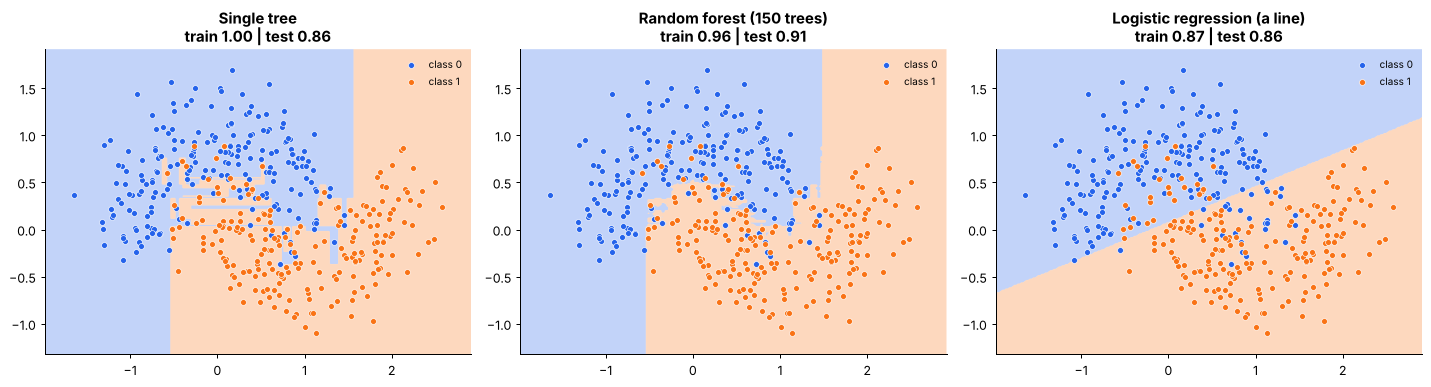

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
plot_decision_boundary(single, Xm_tr, ym_tr, ax=axes[0], title=f"Single tree\ntrain {single.score(Xm_tr, ym_tr):.2f} | test {single.score(Xm_te, ym_te):.2f}")
plot_decision_boundary(ref, Xm_tr, ym_tr, ax=axes[1], title=f"Random forest (150 trees)\ntrain {ref.score(Xm_tr, ym_tr):.2f} | test {ref.score(Xm_te, ym_te):.2f}")
lrm = make_pipeline(StandardScaler(), LogisticRegression()).fit(Xm_tr, ym_tr); plot_decision_boundary(lrm, Xm_tr, ym_tr, ax=axes[2], title=f"Logistic regression (a line)\ntrain {lrm.score(Xm_tr, ym_tr):.2f} | test {lrm.score(Xm_te, ym_te):.2f}")
plt.tight_layout(); plt.show()

---
## 🎛️ 5. Tuning: how many trees, how many features?

We switch to the **loan-approval** problem (same engineered features as Lessons 10–11; `interest_rate_offered` still excluded).

In [6]:
loans = pd.read_csv(data_path("loan_approval.csv"))
loans["dti"] = (loans["monthly_debt_kes"] + loans["loan_amount_kes"] / loans["loan_term_months"] * 1.15) / loans["monthly_income_kes"]
loans["lti"] = loans["loan_amount_kes"] / (loans["monthly_income_kes"] * 12)
loans["log_income"] = np.log(loans["monthly_income_kes"]); loans["log_savings"] = np.log1p(loans["savings_balance_kes"])
num = ["credit_score", "credit_history_years", "dti", "lti", "log_income", "log_savings", "has_collateral", "age", "dependents", "existing_loans"]
X = pd.get_dummies(loans[num + ["employment_type", "property_area", "education"]], drop_first=True, dtype=float); X = X.fillna(X.median())
y = loans["approved"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print("train", Xtr.shape, "| test", Xte.shape, "| approval rate", round(y.mean(), 3))

# reference models
tree_ref = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=0).fit(Xtr, ytr)
lr_ref = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xtr, ytr)
auc = lambda m: roc_auc_score(yte, m.predict_proba(Xte)[:, 1])
print(f"reference test AUC: tuned tree {auc(tree_ref):.3f} | logistic regression {auc(lr_ref):.3f}")

train (2250, 15) | test (750, 15) | approval rate 0.604
reference test AUC: tuned tree 0.863 | logistic regression 0.928


**More trees never hurt.** Using `warm_start`, grow one forest tree-batch by tree-batch and watch the OOB error flatten:

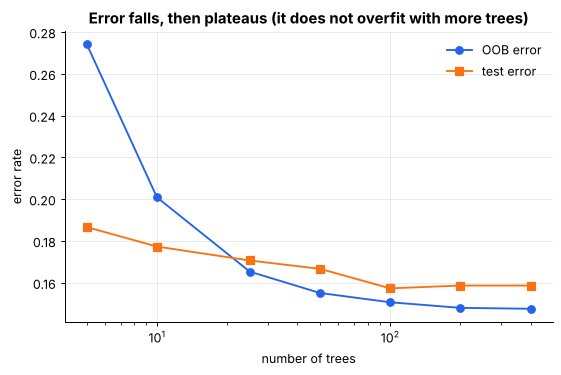

In [7]:
import warnings
rf_w = RandomForestClassifier(warm_start=True, oob_score=True, max_features="sqrt", min_samples_leaf=3, random_state=0, n_jobs=-1)
sizes = [5, 10, 25, 50, 100, 200, 400]; oob_err, test_err = [], []
for n_trees in sizes:
    rf_w.set_params(n_estimators=n_trees)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); rf_w.fit(Xtr, ytr)
    oob_err.append(1 - rf_w.oob_score_); test_err.append(1 - rf_w.score(Xte, yte))
plt.plot(sizes, oob_err, "o-", label="OOB error"); plt.plot(sizes, test_err, "s-", label="test error"); plt.xscale("log"); plt.xlabel("number of trees"); plt.ylabel("error rate"); plt.legend(); plt.title("Error falls, then plateaus (it does not overfit with more trees)"); plt.show()

**`max_features`**: how many columns each split may look at (the decorrelation dial), and **`min_samples_leaf`**: leaf size (the smoothness dial):

In [8]:
rows = []
for mf in ["sqrt", 0.3, 0.5, 0.8, 1.0]:
    for leaf in [1, 5, 20]:
        rf = RandomForestClassifier(150, max_features=mf, min_samples_leaf=leaf, oob_score=True, random_state=0, n_jobs=-1).fit(Xtr, ytr)
        rows.append({"max_features": str(mf), "min_samples_leaf": leaf, "OOB acc": rf.oob_score_, "test AUC": auc(rf)})
grid = pd.DataFrame(rows); display(grid.pivot(index="max_features", columns="min_samples_leaf", values="test AUC").round(3))

min_samples_leaf,1,5,20
max_features,,,
0.3,0.915,0.913,0.914
0.5,0.904,0.909,0.911
0.8,0.901,0.903,0.905
1.0,0.899,0.901,0.901
sqrt,0.912,0.916,0.913


Look at the spread: **every setting lands within about 0.015 AUC of the others**: forests are famously forgiving. The mild trend is that *smaller* `max_features` (√p or 0.3) does slightly better than using all features, because it decorrelates the trees (the lesson of section 1), while leaf size barely matters here. Tune if you need the last fraction of a point, but do not expect miracles from tuning.

---
## 📏 6. Probability quality: calibration

A forest's probability is the average of its trees' leaf proportions. Are those probabilities *honest*? Compare reliability curves (Lesson 09) for three models:

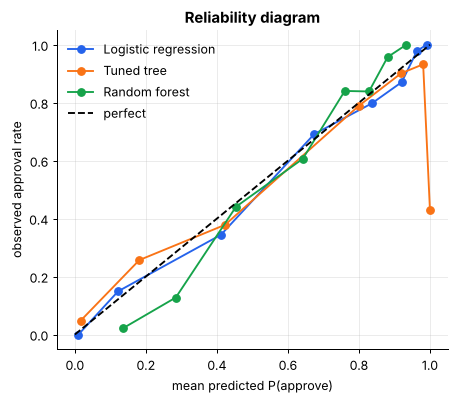

In [9]:
rf_best = RandomForestClassifier(300, max_features="sqrt", min_samples_leaf=10, oob_score=True, random_state=0, n_jobs=-1).fit(Xtr, ytr)
fig, ax = plt.subplots(figsize=(5.6, 4.6))
for name, m in [("Logistic regression", lr_ref), ("Tuned tree", tree_ref), ("Random forest", rf_best)]:
    pt, pp = calibration_curve(yte, m.predict_proba(Xte)[:, 1], n_bins=8, strategy="quantile"); ax.plot(pp, pt, "o-", label=name)
ax.plot([0, 1], [0, 1], "k--", label="perfect"); ax.set_xlabel("mean predicted P(approve)"); ax.set_ylabel("observed approval rate"); ax.legend(); ax.set_title("Reliability diagram"); plt.show()

Logistic regression hugs the diagonal (it optimises log loss directly). The forest is **under-confident at the extremes**: where it says 14 % the true rate is only ≈ 2 %, where it says 76–88 % the truth is higher: averaging pulls probabilities toward the middle, since a leaf is rarely unanimous across *all* trees. The single tree's probabilities are coarse and erratic (look at its last bin collapsing). When honest probabilities matter (pricing, risk), calibrate with `CalibratedClassifierCV` (Platt/isotonic) or prefer logistic regression.

---
## 🏦 7. Loan approvals: forest vs tree vs logistic regression

In [10]:
rows = []
for name, m in [("Logistic regression", lr_ref), ("Tuned decision tree", tree_ref), ("Random forest (leaf=10)", rf_best)]:
    p = m.predict_proba(Xte)[:, 1]; rows.append({"model": name, "accuracy": accuracy_score(yte, p >= .5), "ROC-AUC": roc_auc_score(yte, p), "avg precision": average_precision_score(yte, p)})
display(pd.DataFrame(rows).set_index("model").round(3))
display(pd.DataFrame(confusion_matrix(yte, rf_best.predict(Xte)), index=["actually rejected", "actually approved"], columns=["pred rejected", "pred approved"]))
print(f"OOB accuracy of the forest = {rf_best.oob_score_:.3f}  vs  test accuracy = {rf_best.score(Xte, yte):.3f}")

,accuracy,ROC-AUC,avg precision
model,,,
Logistic regression,0.861,0.928,0.950
Tuned decision tree,0.833,0.863,0.869
Random forest (leaf=10),0.833,0.913,0.940


,pred rejected,pred approved
actually rejected,214,83
actually approved,42,411


OOB accuracy of the forest = 0.851  vs  test accuracy = 0.833


The forest clearly beats the single tree and gets close to logistic regression, which still wins narrowly: the loan decision is generated from (almost) linear log-odds in the engineered ratios: its home turf. That's a recurring theme: **if you can engineer the right features, a simple model is hard to beat; if you can't, forests find the structure for you.** Section 8 shows a problem where the forest wins by a mile.

---
## 🚨 8. Imbalanced data and class weights

Back to the 2 % positive 'fraud' data of Lesson 09: now with a forest. `class_weight='balanced'` re-weights classes inversely to their frequency, so each rare positive counts ~50× more when trees choose splits; `'balanced_subsample'` recomputes the weights within every bootstrap sample.

In [11]:
Xi, yi = make_classification(n_samples=5000, n_features=10, n_informative=5, weights=[0.98, 0.02], flip_y=0.01, class_sep=1.2, random_state=1)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, stratify=yi, random_state=RANDOM_STATE)
rows = []
lr_i = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xi_tr, yi_tr)
rows.append({"model": "Logistic regression", "recall": recall_score(yi_te, lr_i.predict(Xi_te)), "precision": precision_score(yi_te, lr_i.predict(Xi_te), zero_division=0), "PR-AUC": average_precision_score(yi_te, lr_i.predict_proba(Xi_te)[:, 1])})
for cw in [None, "balanced", "balanced_subsample"]:
    rf = RandomForestClassifier(300, min_samples_leaf=2, class_weight=cw, random_state=0, n_jobs=-1).fit(Xi_tr, yi_tr)
    rows.append({"model": f"Random forest, class_weight={cw}", "recall": recall_score(yi_te, rf.predict(Xi_te)), "precision": precision_score(yi_te, rf.predict(Xi_te), zero_division=0), "PR-AUC": average_precision_score(yi_te, rf.predict_proba(Xi_te)[:, 1])})
display(pd.DataFrame(rows).set_index("model").round(3))

,recall,precision,PR-AUC
model,,,
Logistic regression,0.316,0.857,0.465
"Random forest, class_weight=None",0.421,1.000,0.660
"Random forest, class_weight=balanced",0.553,0.913,0.674
"Random forest, class_weight=balanced_subsample",0.395,1.000,0.674


The forest's PR-AUC dwarfs logistic regression's here: this synthetic problem has clustered, non-linear structure that a linear boundary can't express. `class_weight='balanced'` lifts recall at a small precision cost; but the *real* lever for imbalance is usually the **threshold** (Lesson 09): forests output good rankings, you pick the operating point.

---
## 🔎 9. Interpreting the forest: permutation importance

As in Lesson 05, shuffle one feature on the **held-out** set and measure the loss in AUC. We add a pure-noise column as a sanity probe.

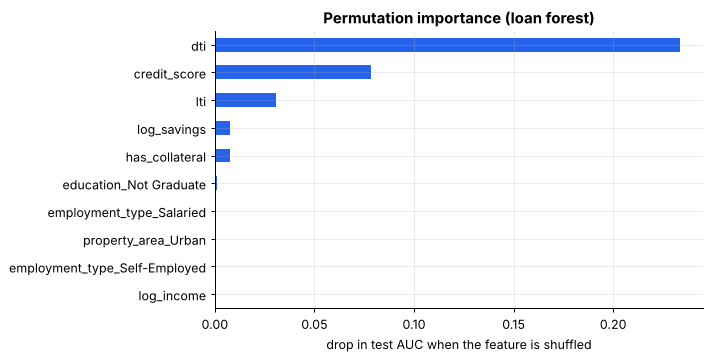

noise column importance: -0.002 | top feature: dti


In [12]:
rng = np.random.default_rng(0)
Xtr_n = Xtr.copy(); Xtr_n["RANDOM_NOISE"] = rng.normal(size=len(Xtr)); Xte_n = Xte.copy(); Xte_n["RANDOM_NOISE"] = rng.normal(size=len(Xte))
rf_n = RandomForestClassifier(300, max_features="sqrt", min_samples_leaf=10, random_state=0, n_jobs=-1).fit(Xtr_n, ytr)
pi = permutation_importance(rf_n, Xte_n, yte, scoring="roc_auc", n_repeats=10, random_state=0, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Xte_n.columns).sort_values()
colors = ["#dc2626" if i == "RANDOM_NOISE" else "#2563eb" for i in imp.index]
imp.tail(10).plot.barh(color=colors[-10:], figsize=(7, 4)); plt.xlabel("drop in test AUC when the feature is shuffled"); plt.title("Permutation importance (loan forest)"); plt.show()
print("noise column importance:", round(imp["RANDOM_NOISE"], 4), "| top feature:", imp.index[-1])

---
## 📋 10. Cheat-sheet: the full profile of Random Forest Classification

| Question | Answer |
|---|---|
| **Underlying concept** | A committee of many deep, diverse decision trees; the class with the most (probability-weighted) votes wins. |
| **How it works** | For each tree: bootstrap the rows, grow a tree choosing each split from a random subset of `max_features` columns. Predict by averaging the trees' class probabilities. OOB rows give a free validation estimate. |
| **Mathematical foundation** | Condorcet jury theorem; variance of an average of correlated estimators ρσ²+(1−ρ)σ²/B; bootstrap (≈63 % in-bag); Gini/entropy splits; OOB estimation. |
| **Important parameters** | `n_estimators`, `max_features` (√p default), `min_samples_leaf`, `max_depth`, `class_weight` (balanced / balanced_subsample), `bootstrap`, `max_samples`, `oob_score`, `n_jobs`, `random_state`. |
| **Advantages** | Strong out-of-the-box accuracy; robust to noise and irrelevant features; no scaling; handles non-linearity and interactions; OOB score; importances; parallelisable; works for multi-class. |
| **Disadvantages** | Less interpretable than a single tree or logistic regression; probabilities need calibration; large and slower than linear models; can lose to a well-specified linear model; weak on sparse high-dim text. |
| **Complexity** | Training ≈ O(B · √p · n log n) (parallel across trees); prediction O(B · depth); memory O(B · nodes). |
| **Use cases** | Tabular classification with mixed feature types: fraud, churn, risk, diagnostics, quick strong baselines for almost any structured problem. |
| **Limitations** | Importances can mislead with correlated features; no extrapolation; biased towards frequent classes without weights; many trees = bigger deployment footprint. |

---
## 🧪 11. Worked examples

### Worked Example 1: Majority of 3

Three independent classifiers, each correct with probability $p=0.7$. The majority is right if at least 2 are right:

$$P=\binom32(0.7)^2(0.3)+\binom33(0.7)^3=3(0.49)(0.3)+0.343=0.441+0.343=\mathbf{0.784}$$

A committee of just three mediocre voters beats each one (0.70) by 8 points. With 11 voters it is 0.92.

In [13]:
print("P(majority of 3) =", round(binom.sf(1, 3, 0.7), 4), "| of 11 =", round(binom.sf(5, 11, 0.7), 4))

P(majority of 3) = 0.784 | of 11 = 0.9218


### Worked Example 2: Soft voting with three trees

Tree probabilities for (approve, reject): Tree A (0.9, 0.1), Tree B (0.4, 0.6), Tree C (0.45, 0.55). Hard votes: approve, reject, reject → **reject** (2–1). Soft average: approve $=(0.9+0.4+0.45)/3=0.583$ → **approve**. Soft voting sides with the confident tree.

---
### 🧩 Problem 1: Condorcet by the binomial  ⭐

Using `scipy.stats.binom` (already imported), compute the probability that a **majority** of `n` independent voters is correct, each with accuracy `p`:

- `p_11` for n = 11, p = 0.6
- `p_101` for n = 101, p = 0.6
- `p_101_weak` for n = 101, p = 0.52
- `n_needed` = the smallest **odd** n for which the majority (p = 0.6) is correct at least 90 % of the time.

In [14]:
# ✅ SOLUTION
p_11 = binom.sf(11 // 2, 11, 0.6); p_101 = binom.sf(101 // 2, 101, 0.6); p_101_weak = binom.sf(101 // 2, 101, 0.52)
n_needed = next(n for n in range(1, 2000, 2) if binom.sf(n // 2, n, 0.6) >= 0.9)
print(round(p_11, 4), round(p_101, 4), round(p_101_weak, 4), n_needed)

0.7535 0.9791 0.6566 41


**Why this works.** Voters barely better than chance (p = 0.52) lift a crowd of 101 only to about 66 %: you would need roughly a thousand of them to reach 90 %. Individual competence matters as well as independence. At p = 0.6, just 41 independent voters already reach 90 %.

In [15]:
check("11 voters, p=0.6 -> about 0.753", lambda: abs(p_11 - 0.7535) < 1e-3)
check("101 voters, p=0.6 -> about 0.98", lambda: p_101 > 0.97)
check("101 voters, p=0.52 -> only about 0.66", lambda: 0.62 < p_101_weak < 0.70)
check("about 41 voters are enough for 90%", lambda: n_needed == 41)

✅  11 voters, p=0.6 -> about 0.753
✅  101 voters, p=0.6 -> about 0.98
✅  101 voters, p=0.52 -> only about 0.66
✅  about 41 voters are enough for 90%


---
### 🧩 Problem 2: Hard vs soft voting  ⭐⭐

Given `probs`, an array of shape (5 trees, 4 samples) holding each tree's P(class 1) for 4 samples:
```python
probs = np.array([[0.95, 0.55, 0.20, 0.51],
                  [0.90, 0.55, 0.30, 0.51],
                  [0.35, 0.60, 0.45, 0.52],
                  [0.30, 0.52, 0.40, 0.02],
                  [0.40, 0.51, 0.35, 0.05]])
```
Compute `soft_pred` (class 1 if the mean probability ≥ 0.5) and `hard_pred` (class 1 if **more than half** of the trees have probability ≥ 0.5) for each sample (arrays of 0/1). Store `disagree` = the indices of the samples where they differ.

In [16]:
# ✅ SOLUTION
probs = np.array([[0.95, 0.55, 0.20, 0.51], [0.90, 0.55, 0.30, 0.51], [0.35, 0.60, 0.45, 0.52], [0.30, 0.52, 0.40, 0.02], [0.40, 0.51, 0.35, 0.05]])
soft_pred = (probs.mean(axis=0) >= 0.5).astype(int)
hard_pred = ((probs >= 0.5).mean(axis=0) > 0.5).astype(int)
disagree = np.where(soft_pred != hard_pred)[0]
print(soft_pred, hard_pred, disagree)

[1 1 0 0] [0 1 0 1] [0 3]


**Why this works.** Sample 0: only 2 of 5 trees vote class 1, but those two are very confident (0.95, 0.90), so the *average* (0.58) says class 1: soft voting listens to confidence. Sample 3: 3 of 5 trees barely cross 0.5 while two trees say ≈ 0, so hard voting says class 1 but the mean (0.32) says class 0. Soft voting generally uses more information, which is why scikit-learn's forest averages probabilities.

In [17]:
check("soft predictions = [1, 1, 0, 0]", lambda: list(soft_pred) == [1, 1, 0, 0])
check("hard predictions = [0, 1, 0, 1]", lambda: list(hard_pred) == [0, 1, 0, 1])
check("the rules disagree on samples 0 and 3", lambda: list(disagree) == [0, 3])

✅  soft predictions = [1, 1, 0, 0]
✅  hard predictions = [0, 1, 0, 1]
✅  the rules disagree on samples 0 and 3


---
### 🧩 Problem 3: Fit a forest and beat the tree  ⭐

Fit `RandomForestClassifier(300, max_features='sqrt', min_samples_leaf=10, oob_score=True, random_state=0, n_jobs=-1)` on the loan data `Xtr, ytr`. Store `oob_acc`, `test_acc`, `auc_rf` (test ROC-AUC) and `gain_over_tree = auc_rf - auc(tree_ref)` (the lesson's `auc` helper and `tree_ref`).

In [18]:
# ✅ SOLUTION
rf1 = RandomForestClassifier(300, max_features="sqrt", min_samples_leaf=10, oob_score=True, random_state=0, n_jobs=-1).fit(Xtr, ytr)
oob_acc = rf1.oob_score_; test_acc = rf1.score(Xte, yte); auc_rf = auc(rf1); gain_over_tree = auc_rf - auc(tree_ref)
print(round(oob_acc, 3), round(test_acc, 3), round(auc_rf, 3), round(gain_over_tree, 3))

0.851 0.833 0.913 0.05


**Why this works.** Averaging 300 diverse trees cuts variance: the forest gains a few AUC points over even a well-tuned single tree, and its OOB score agrees with the held-out test accuracy.

In [19]:
check("OOB accuracy tracks test accuracy (gap < 0.04)", lambda: abs(oob_acc - test_acc) < 0.04)
check("forest AUC > 0.91", lambda: auc_rf > 0.91)
check("forest beats the tuned tree by > 0.02 AUC", lambda: gain_over_tree > 0.02)

✅  OOB accuracy tracks test accuracy (gap < 0.04)
✅  forest AUC > 0.91
✅  forest beats the tuned tree by > 0.02 AUC


---
### 🧩 Problem 4: Tune with randomised search  ⭐⭐

Use `RandomizedSearchCV` (`n_iter=8`, `cv=StratifiedKFold(3, shuffle=True, random_state=0)`, `scoring='roc_auc'`, `random_state=0`, `n_jobs=-1`) on `RandomForestClassifier(n_estimators=150, random_state=0)` over `max_features ∈ ['sqrt', 0.3, 0.5]`, `min_samples_leaf ∈ [1, 3, 5, 10, 20]`, `max_depth ∈ [None, 8, 12]`. Store `best_params` and the test AUC `tuned_auc`.

In [20]:
# ✅ SOLUTION
rs = RandomizedSearchCV(RandomForestClassifier(n_estimators=150, random_state=0), {"max_features": ["sqrt", 0.3, 0.5], "min_samples_leaf": [1, 3, 5, 10, 20], "max_depth": [None, 8, 12]},
                        n_iter=8, cv=StratifiedKFold(3, shuffle=True, random_state=0), scoring="roc_auc", random_state=0, n_jobs=-1).fit(Xtr, ytr)
best_params = rs.best_params_; tuned_auc = roc_auc_score(yte, rs.best_estimator_.predict_proba(Xte)[:, 1])
print(best_params, round(tuned_auc, 3))

{'min_samples_leaf': 10, 'max_features': 0.5, 'max_depth': 8} 0.911


**Why this works.** Randomised search tests a random subset of the grid and is far cheaper than a full grid. Because forests are forgiving, many different settings score within a hair of each other: the gain from tuning is small but cheap.

In [21]:
check("three hyper-parameters searched", lambda: set(best_params) == {"max_features", "min_samples_leaf", "max_depth"})
check("tuned test AUC > 0.91", lambda: tuned_auc > 0.91)

✅  three hyper-parameters searched
✅  tuned test AUC > 0.91


---
### 🧩 Problem 5: Class weights on imbalanced data  ⭐⭐

On the fraud data (`Xi_tr, yi_tr, Xi_te, yi_te`) fit two forests `RandomForestClassifier(300, min_samples_leaf=2, random_state=0, n_jobs=-1)`: one with `class_weight=None` and one with `class_weight='balanced'`. Store each one's **recall** at the default 0.5 threshold (`recall_plain`, `recall_bal`), and the PR-AUC of the plain forest `ap_plain` and of **logistic regression** (`lr_i` from the lesson) `ap_lr`.

In [22]:
# ✅ SOLUTION
mk = lambda cw: RandomForestClassifier(300, min_samples_leaf=2, class_weight=cw, random_state=0, n_jobs=-1).fit(Xi_tr, yi_tr)
rf_p, rf_b = mk(None), mk("balanced")
recall_plain = recall_score(yi_te, rf_p.predict(Xi_te)); recall_bal = recall_score(yi_te, rf_b.predict(Xi_te))
ap_plain = average_precision_score(yi_te, rf_p.predict_proba(Xi_te)[:, 1]); ap_lr = average_precision_score(yi_te, lr_i.predict_proba(Xi_te)[:, 1])
print(recall_plain, recall_bal, ap_plain, ap_lr)

0.42105263157894735 0.5526315789473685 0.6600912519271199 0.4645107288827772


**Why this works.** Weighting rare positives makes trees split to isolate them (more recall). The bigger story: on this non-linear imbalanced problem the forest's ranking quality (PR-AUC) is far better than a linear model's.

In [23]:
check("balanced class weights raise recall", lambda: recall_bal > recall_plain)
check("the forest beats logistic regression on PR-AUC here", lambda: ap_plain > ap_lr + 0.1)

✅  balanced class weights raise recall
✅  the forest beats logistic regression on PR-AUC here


---
### 🧩 Problem 6: Top drivers by permutation importance  ⭐⭐

Using the lesson's `rf_n`, `Xte_n`, `yte`: compute permutation importance with `scoring='roc_auc'`, `n_repeats=10`, `random_state=1`. Store the **top three feature names** in `top3` (most important first), `noise_imp` = the importance of `RANDOM_NOISE`, and `n_useless` = the number of features whose mean importance is **below 0.001**.

In [24]:
# ✅ SOLUTION
pi2 = permutation_importance(rf_n, Xte_n, yte, scoring="roc_auc", n_repeats=10, random_state=1, n_jobs=-1)
imp2 = pd.Series(pi2.importances_mean, index=Xte_n.columns).sort_values(ascending=False)
top3 = imp2.index[:3].tolist(); noise_imp = imp2["RANDOM_NOISE"]; n_useless = int((imp2 < 0.001).sum())
print(top3, round(noise_imp, 4), n_useless)

['dti', 'credit_score', 'lti'] -0.0026 11


**Why this works.** Credit score and debt-to-income dominate: exactly the drivers logistic regression found in Lesson 10. Two very different models agreeing on the drivers is strong evidence the signal is real.

In [25]:
check("credit_score and dti are among the top 3", lambda: "credit_score" in top3 and "dti" in top3)
check("the noise column is (almost) useless", lambda: noise_imp < 0.005)
check("several features are essentially irrelevant", lambda: n_useless >= 3)

✅  credit_score and dti are among the top 3
✅  the noise column is (almost) useless
✅  several features are essentially irrelevant


---
## 🧠 Check Your Understanding
Answer each question in your head (or on paper) *before* opening the answer.

**Q1.** 101 jurors, each right 60 % of the time but all copying the same newspaper. Is the majority 98 % reliable?

<details><summary>👀 Show answer</summary>

No. Condorcet's result needs independent errors. Heavily correlated voters make one decision many times; the ensemble's accuracy is capped near the individual accuracy.

</details>

**Q2.** Why does a forest use random feature subsets *in addition to* bootstrap samples?

<details><summary>👀 Show answer</summary>

Bootstrapping alone yields similar trees when a few features dominate (they'd all split on them first). Random subsets force diversity, lowering tree-to-tree correlation ρ.

</details>

**Q3.** What does `class_weight='balanced'` do to the trees' splits?

<details><summary>👀 Show answer</summary>

It scales each sample's weight inversely to its class frequency, so rare-class mistakes cost much more in the impurity calculation and splits try harder to isolate the rare class.

</details>

**Q4.** The forest's probabilities are never exactly 0 or 1 even for easy cases. Why, and what to do if you need calibrated probabilities?

<details><summary>👀 Show answer</summary>

Probabilities are averages over many trees, so unanimous 0/1 across all trees is rare (and leaves with min_samples_leaf > 1 are mixed). Calibrate with CalibratedClassifierCV or use logistic regression.

</details>

**Q5.** When would you pick logistic regression over a forest?

<details><summary>👀 Show answer</summary>

When the relationship is (nearly) linear in good features, when you need honest probabilities and explainable coefficients, with very small data, or for strict latency/size limits.

</details>

---
## 🔁 Recap

- A Random Forest classifier = bootstrap + random feature subsets + soft-voting over many deep trees.
- Condorcet: independent better-than-chance voters become excellent as a group; correlation sets the ceiling, so diversity is the design goal.
- More trees never hurt; tune `min_samples_leaf`, `max_features`; use `class_weight` + threshold/PR-AUC for imbalance.
- OOB accuracy is a free validation score; permutation importance (held-out) tells you what the model relies on.
- Forests are a superb default, but probabilities need calibration and a well-specified linear model can still win.

### ➡️ Up next: **K-Nearest Neighbors Classification**
Open `13_KNN_Classification.ipynb` when you're ready.

*You did the hard part: you thought about it, not just ran it. See you in the next one!* 🚀